In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\NEHA\Downloads\creditcard.csv.zip")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
# Check dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nFraud and Genuine Transactions:")
print(df["Class"].value_counts())

Dataset Shape: (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing Values:
0

Fraud and Genuine Transactions:
Class
0    284315
1       492
Name: count, dtype: int64


Genuine Transactions: 284315
Fraud Transactions: 492
Fraud Percentage: 0.1727%


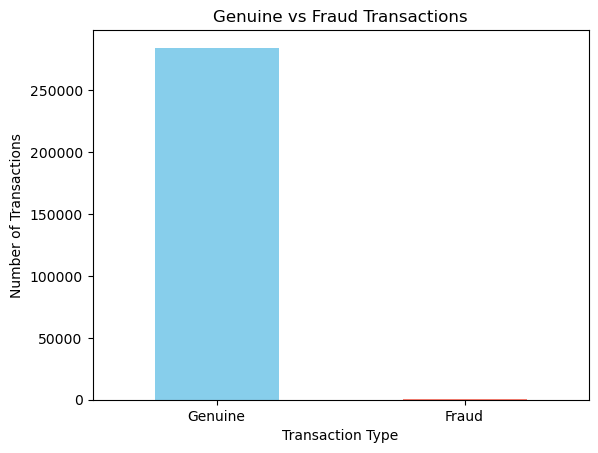

In [3]:
# Calculate transaction distribution
class_counts = df["Class"].value_counts()

print("Genuine Transactions:", class_counts[0])
print("Fraud Transactions:", class_counts[1])

fraud_percentage = (class_counts[1] / len(df)) * 100
print(f"Fraud Percentage: {fraud_percentage:.4f}%")

# Visualize the class distribution
import matplotlib.pyplot as plt

class_counts.rename({
    0: "Genuine",
    1: "Fraud"
}).plot(kind="bar", color=["skyblue", "salmon"])

plt.title("Genuine vs Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

Genuine Transaction Amounts:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraud Transaction Amounts:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


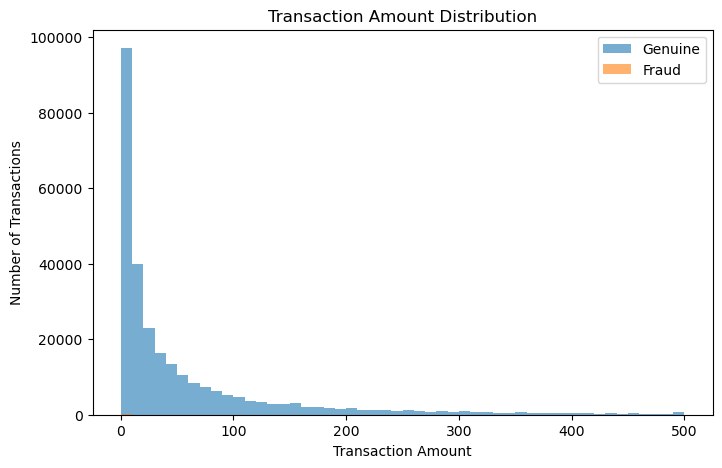

In [4]:
# Compare transaction amounts
print("Genuine Transaction Amounts:")
print(df[df["Class"] == 0]["Amount"].describe())

print("\nFraud Transaction Amounts:")
print(df[df["Class"] == 1]["Amount"].describe())

# Visualize transaction amount distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df[df["Class"] == 0]["Amount"],
    bins=50,
    alpha=0.6,
    label="Genuine",
    range=(0, 500)
)

plt.hist(
    df[df["Class"] == 1]["Amount"],
    bins=50,
    alpha=0.6,
    label="Fraud",
    range=(0, 500)
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.legend()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nFraud cases in training:", y_train.sum())
print("Fraud cases in testing:", y_test.sum())

Training data: (227845, 30)
Testing data: (56962, 30)

Fraud cases in training: 394
Fraud cases in testing: 98


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score, roc_auc_score

# Create a model pipeline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("PR-AUC (Average Precision):",
      average_precision_score(y_test, y_prob))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

Confusion Matrix:
[[55478  1386]
 [    8    90]]
PR-AUC (Average Precision): 0.7189705771419241
ROC-AUC: 0.9720834996210077


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score, roc_auc_score

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("PR-AUC:", average_precision_score(y_test, rf_prob))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56861     3]
 [   25    73]]
PR-AUC: 0.8541999432510914
ROC-AUC: 0.952908497036969


                 Model  Precision  Recall  F1-score   PR-AUC
0  Logistic Regression       0.06    0.92      0.11  0.71897
1        Random Forest       0.96    0.74      0.84  0.85420


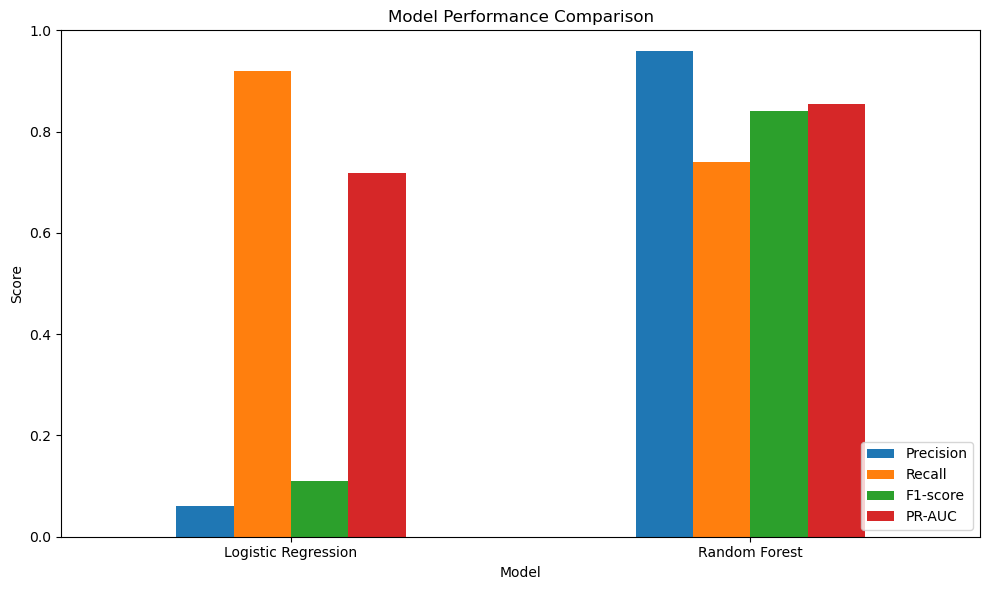

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [0.06, 0.96],
    "Recall": [0.92, 0.74],
    "F1-score": [0.11, 0.84],
    "PR-AUC": [0.71897, 0.85420]
})

print(comparison)

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Top 10 Important Features:
   Feature  Importance
14     V14    0.179857
10     V10    0.115442
12     V12    0.096206
4       V4    0.095646
17     V17    0.095113
3       V3    0.068669
11     V11    0.056112
16     V16    0.040303
2       V2    0.036265
9       V9    0.026888


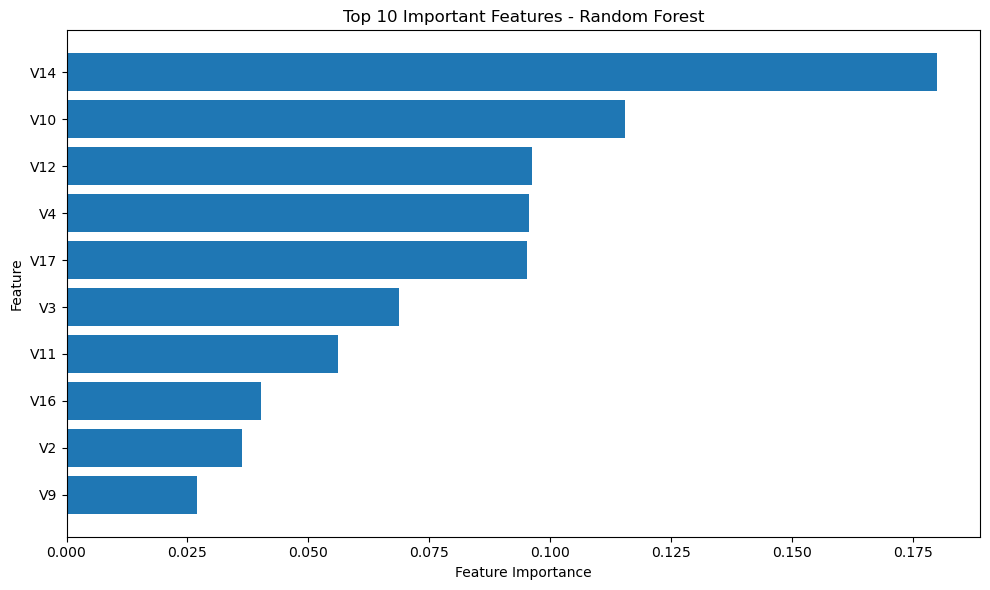

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from Random Forest
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
print(importance.head(10))

# Plot top 10 features
top_features = importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

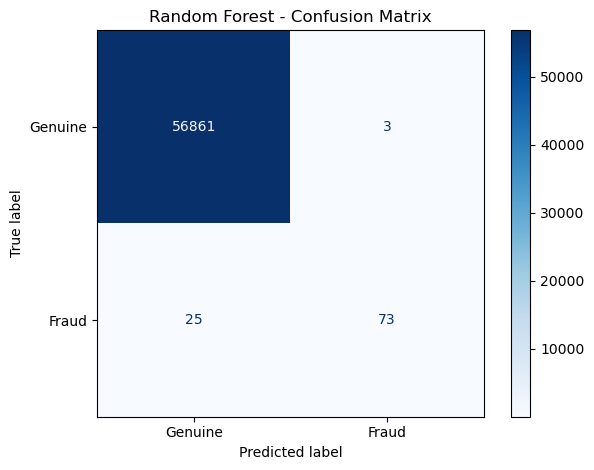

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Genuine", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
# Save model comparison results
comparison.to_csv("task6_model_comparison.csv", index=False)

# Save feature importance results
importance.to_csv("task6_feature_importance.csv", index=False)

print("Model comparison saved successfully!")
print("Feature importance saved successfully!")

Model comparison saved successfully!
Feature importance saved successfully!


In [13]:
import os

print("Current Folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current Folder:
C:\Users\NEHA

Files in this folder:
[' task2 Analysis.ipynb', '.anaconda', '.conda', '.continuum', '.copilot', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.streamlit', '.vscode', '.vscode-shared', '1s ttry', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'archive.zip', 'Contacts', 'Cookies', 'covid_19.csv', 'CrossDevice', 'Documents', 'Downloads', 'Favorites', 'Links', 'loan_approval_model.pkl', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{08ec57b9-c4c9-11f0-b65f-502e91eb7e03}.TM.blf', 'NTUSER.DAT{08ec57b9-c4c9-11f0-b65f-502e91eb7e03}.TM.blf.cnpf', 'NTUSER.DAT{08ec57b9-c4c9-11f0-b65f-502e91eb7e03}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{08ec57b9-c4c9-11f0-b65f-502e91eb7e03}.TMContainer00000000000000000001.regtrans-ms.cnpf', 'NTUSER.DAT{08ec57b9-c4c9-11f0-b65f-502e91eb7e03}.TMContainer00000000000000000002.regtrans-ms', 'NTUSER.DAT{08ec57b9-c4c9-